# Model 4: Gated Recurrent Unit (GRU) Network
### B.Tech Mini Project: Aircraft Engine Predictive Maintenance (NASA C-MAPSS FD001)

This notebook implements **Model 4 (GRU)** as part of our controlled five-model architectural benchmark:
1. **Linear Regression (Baseline)** *(Notebook 06)*
2. **Random Forest** *(Notebook 07)*
3. **Long Short-Term Memory (LSTM)** *(Notebook 08)*
4. **Gated Recurrent Unit (GRU)** *(this notebook)*
5. **1D-CNN** *(Notebook 10)*

#### Progressive Benchmark Context
In Notebook 08, we demonstrated that preserving the raw 3D sequence structure `(batch_size, 30, 17)` using recurrent gating (LSTM) produced a decisive improvement over flattened tabular baselines, reducing validation RMSE from ~15.76–16.07 cycles down to ~13.48 cycles.

In this notebook, we evaluate the **Gated Recurrent Unit (GRU)**, a modernized recurrent architecture introduced by Cho et al. (2014). GRU streamlines recurrent memory dynamics by replacing the three separate LSTM gates and distinct cell state with two coupled gates (**Reset** and **Update**), reducing parameters by ~24% while retaining full long-range temporal modeling capability.

#### Nine-Stage Systematic Workflow:
1. **Stage 1 - Reproduce Dataset Pipeline:** Re-execute self-contained preprocessing, engine-wise 80/20 partitioning, feature selection (17 features), StandardScaler fitting, and window extraction ($W=30$, stride=1).
2. **Stage 2 - Theoretical Context:** Detailed theoretical exploration of recurrent networks, engine degradation dynamics, GRU cell equations, gating mechanics, and comparison with LSTM.
3. **Stage 3 - Architecture Construction:** Build the two-layer stacked GRU network using the Keras Sequential API matching specifications.
4. **Stage 4 - Training Configuration & Execution:** Configure Adam optimizer, MSE loss, RMSE metric, and EarlyStopping with `restore_best_weights=True`. Train on CPU with strict test isolation.
5. **Stage 5 - Training Visualizations:** Plot learning curves (loss and RMSE) across epochs to identify convergence and overfitting inception.
6. **Stage 6 - Metric Evaluation:** Calculate RMSE, total NASA score, and NASA score per sample on training and validation partitions with numerical safeguards.
7. **Stage 7 - Comparative Analysis:** Benchmark Model 4 (GRU) against Model 1 (Linear Regression), Model 2 (Random Forest), and Model 3 (LSTM).
8. **Stage 8 - Systematic Integrity Checks:** Execute formal assertions verifying tensor dimensionality, lack of NaNs/infs, test isolation, and model properties.

In [1]:
import os
import random
from pathlib import Path

# Configure writable cache directories inside sandbox
os.environ["KERAS_HOME"] = "/tmp/.keras"
os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Dropout, GRU, Input
from tensorflow.keras.models import Sequential

# Visual styling for academic figures
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

# Fix random seeds for exact reproducibility across libraries
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

print("=" * 65)
print("ENVIRONMENT INITIALIZED FOR CPU REPRODUCIBILITY")
print("=" * 65)
print(f"TensorFlow version : {tf.__version__}")
print(f"Random seed set to : {SEED}")
print(f"Target device      : CPU execution")
print("=" * 65)

ENVIRONMENT INITIALIZED FOR CPU REPRODUCIBILITY
TensorFlow version : 2.21.0
Random seed set to : 42
Target device      : CPU execution


---
## Stage 1: Reproduce the Exact Dataset Pipeline

To guarantee that this notebook is completely self-contained and operates independently of other notebook kernel sessions, we re-execute the exact preprocessing pipeline established in notebooks `03`, `04`, and `05`:

1. **Ingestion:** Load `train_FD001.txt`, `test_FD001.txt`, and `RUL_FD001.txt` using the standard 26-column schema (`unit`, `cycle`, 3 operating settings, 21 sensors).
2. **Target Labeling:** Calculate piecewise linear capped Remaining Useful Life:
   $$RUL = \min(125, \max(\text{cycle}) - \text{cycle})$$
3. **Engine-Wise Split:** Partition unique engine units into 80 training engines ($80\%$) and 20 validation engines ($20\%$) using `train_test_split(..., test_size=0.20, random_state=42)`.
4. **Feature Selection:** Prune 7 exact zero-variance features on the training split while retaining `sensor_6` (17 selected features).
5. **Feature Scaling:** Fit `StandardScaler` strictly on the 80 training engines, transforming training, validation, and test sets to prevent data leakage.
6. **Sliding Windows ($W=30$, Stride=1):** Extract 30-cycle temporal windows for training and validation, pairing each sequence with the target RUL at the final time step.
7. **Test Window Formulation:** Extract exactly one final 30-cycle window for each of the 100 test engines, paired with true ground-truth RUL from `rul_df`.
   > [!IMPORTANT]
   > Test sequences `(X_test, y_test)` are retained for final benchmarking but are **strictly untouched** during model training, hyperparameter tuning, and validation.

In [2]:
# 1. Define schema
columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# 2. Resolve dataset directory
DATA_DIR = Path("../data/raw/CMaps") if Path("../data/raw/CMaps").exists() else Path("data/raw/CMaps")

# 3. Ingest raw datasets
train_df = pd.read_csv(DATA_DIR / "train_FD001.txt", sep=r"\s+", header=None, names=columns)
test_df = pd.read_csv(DATA_DIR / "test_FD001.txt", sep=r"\s+", header=None, names=columns)
rul_df = pd.read_csv(DATA_DIR / "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

# 4. Calculate piecewise linear capped RUL (cap = 125)
train_df["max_cycle"] = train_df.groupby("unit")["cycle"].transform("max")
train_df["raw_RUL"] = train_df["max_cycle"] - train_df["cycle"]
train_df["RUL"] = np.minimum(125, train_df["raw_RUL"])

# 5. Engine-wise split (80 train engines, 20 validation engines, random_state=42)
unique_units = train_df["unit"].unique()
train_units, val_units = train_test_split(unique_units, test_size=0.20, random_state=42)

train_split_df = train_df[train_df["unit"].isin(train_units)].copy().reset_index(drop=True)
val_split_df = train_df[train_df["unit"].isin(val_units)].copy().reset_index(drop=True)

# 6. Feature selection strictly on training partition
candidate_features = [f"op_setting_{i}" for i in range(1, 4)] + [f"sensor_{i}" for i in range(1, 22)]
train_var = train_split_df[candidate_features].var()
train_nunique = train_split_df[candidate_features].nunique()
zero_var_features = [f for f in candidate_features if train_nunique[f] == 1 or train_var[f] < 1e-12]
selected_features = [f for f in candidate_features if f not in zero_var_features]

# 7. Fit StandardScaler strictly on training partition and transform all partitions
scaler = StandardScaler()
train_split_df[selected_features] = scaler.fit_transform(train_split_df[selected_features])
val_split_df[selected_features] = scaler.transform(val_split_df[selected_features])
test_df[selected_features] = scaler.transform(test_df[selected_features])

# 8. Sliding window extraction (Window length = 30 cycles, stride = 1)
WINDOW_SIZE = 30

def extract_windows(df, seq_len, feature_cols, target_col="RUL"):
    X_list, y_list = [], []
    for unit, group in df.groupby("unit"):
        group_sorted = group.sort_values("cycle").reset_index(drop=True)
        features = group_sorted[feature_cols].values
        targets = group_sorted[target_col].values
        for i in range(len(group_sorted) - seq_len + 1):
            X_list.append(features[i : i + seq_len])
            y_list.append(targets[i + seq_len - 1])
    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.float32)

X_train, y_train = extract_windows(train_split_df, WINDOW_SIZE, selected_features)
X_val, y_val = extract_windows(val_split_df, WINDOW_SIZE, selected_features)

# Extract exactly one final 30-cycle window per test engine
X_test_list, y_test_list = [], []
for unit, group in test_df.groupby("unit"):
    group_sorted = group.sort_values("cycle").reset_index(drop=True)
    assert len(group_sorted) >= WINDOW_SIZE, f"Test unit {unit} has fewer than {WINDOW_SIZE} cycles!"
    X_test_list.append(group_sorted[selected_features].values[-WINDOW_SIZE:])
    y_test_list.append(float(rul_df.iloc[unit - 1]["RUL"]))

X_test = np.array(X_test_list, dtype=np.float32)
y_test = np.array(y_test_list, dtype=np.float32)

# Formal assertions verifying strict pipeline integrity
assert X_train.shape == (14241, 30, 17), f"X_train shape error: {X_train.shape}"
assert y_train.shape == (14241,), f"y_train shape error: {y_train.shape}"
assert X_val.shape == (3490, 30, 17), f"X_val shape error: {X_val.shape}"
assert y_val.shape == (3490,), f"y_val shape error: {y_val.shape}"
assert X_test.shape == (100, 30, 17), f"X_test shape error: {X_test.shape}"
assert y_test.shape == (100,), f"y_test shape error: {y_test.shape}"
assert len(set(train_units).intersection(set(val_units))) == 0, "Engine overlap between train and val!"
assert not np.isnan(X_train).any() and not np.isnan(y_train).any(), "NaN in train data!"
assert not np.isnan(X_val).any() and not np.isnan(y_val).any(), "NaN in val data!"
assert not np.isnan(X_test).any() and not np.isnan(y_test).any(), "NaN in test data!"
assert not np.isinf(X_train).any() and not np.isinf(y_train).any(), "Inf in train data!"
assert not np.isinf(X_val).any() and not np.isinf(y_val).any(), "Inf in val data!"
assert not np.isinf(X_test).any() and not np.isinf(y_test).any(), "Inf in test data!"
assert len(selected_features) == 17, f"Selected feature count error: {len(selected_features)}"
assert "sensor_6" in selected_features, "sensor_6 was unexpectedly dropped!"

print("=" * 65)
print("STAGE 1: PIPELINE REPRODUCED & TENSOR SHAPES CONFIRMED")
print("=" * 65)
print(f"X_train shape : {X_train.shape}  | y_train shape : {y_train.shape}")
print(f"X_val shape   : {X_val.shape}   | y_val shape   : {y_val.shape}")
print(f"X_test shape  : {X_test.shape}    | y_test shape  : {y_test.shape} (retained un-evaluated)")
print(f"Engine Counts : Train = {len(train_units)}, Validation = {len(val_units)}, Test = {len(X_test)}")
print(f"Features (17) : {selected_features}")
print("✓ Check: Zero NaNs, zero infinities, zero engine leakage.")
print("=" * 65)

STAGE 1: PIPELINE REPRODUCED & TENSOR SHAPES CONFIRMED
X_train shape : (14241, 30, 17)  | y_train shape : (14241,)
X_val shape   : (3490, 30, 17)   | y_val shape   : (3490,)
X_test shape  : (100, 30, 17)    | y_test shape  : (100,) (retained un-evaluated)
Engine Counts : Train = 80, Validation = 20, Test = 100
Features (17) : ['op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
✓ Check: Zero NaNs, zero infinities, zero engine leakage.


---
## Stage 2: Understanding Gated Recurrent Unit (GRU) Networks

### 1. Motivation: Recurrent Modeling of Temporal Degradation
Turbofan engine wear is an inherently **continuous temporal process**. A static sensor reading in isolation (e.g., high-pressure compressor outlet temperature $T_{30} = 1590^\circ\text{R}$) lacks critical diagnostic context:
- If $T_{30}$ has remained steady at $1590^\circ\text{R}$ across 30 operational cycles, the engine is in a stable operating regime.
- If $T_{30}$ has climbed sharply from $1550^\circ\text{R}$ to $1590^\circ\text{R}$ over the previous 10 cycles, rapid compressor fouling or thermal barrier breakdown is underway.

To capture the **velocity** and **acceleration** of sensor degradation, a predictive maintenance model must analyze time-series sequences.

---

### 2. What is a Gated Recurrent Unit (GRU)?
The **Gated Recurrent Unit (GRU)** was introduced by Cho et al. in 2014 as an elegant, computationally streamlined alternative to the Long Short-Term Memory (LSTM) cell. 

While both architectures conquer the *vanishing gradient problem* inherent in standard RNNs by using internal gating mechanisms, GRU alters the internal gating topology to achieve comparable modeling capacity with fewer parameters and lower computational overhead.

---

### 3. Architectural Comparison: GRU vs. LSTM

| Architectural Feature | Long Short-Term Memory (LSTM) | Gated Recurrent Unit (GRU) | Physical Impact on RUL Modeling |
| :--- | :--- | :--- | :--- |
| **Number of Gates** | **3 gates:** Forget ($f_t$), Input ($i_t$), Output ($o_t$) | **2 gates:** Reset ($r_t$), Update ($z_t$) | Fewer gate activations per step; lower latency. |
| **Memory State Structure** | Decoupled **Cell State ($C_t$)** and **Hidden State ($h_t$)** | Single unified **Hidden State ($h_t$)** | Simplified state tracking; no redundant memory channels. |
| **Memory Retention Mechanism** | Separate forget and input gating ($C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t$) | Coupled convex combination: $(1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t$ | Eliminates conflicting simultaneous write/erase decisions. |
| **Parameter Count** | $4 \times (d_{in} + d_{out} + 1) \times d_{out}$ | $3 \times (d_{in} + d_{out} + 1) \times d_{out}$ | **~24% to 25% fewer parameters**; reduced overfitting risk. |
| **Training Throughput** | Higher memory footprint and slower backprop | Faster per-epoch step time and lower cache overhead | Ideal for deployment on resource-constrained embedded systems. |

---

### 4. Mathematical Formulation of the GRU Cell
At each cycle $t \in [1, 30]$, given input vector $x_t \in \mathbb{R}^{17}$ and previous hidden state $h_{t-1} \in \mathbb{R}^{d}$:

$$\begin{aligned}
\text{1. Reset Gate:} \quad r_t &= \sigma\left(W_r x_t + U_r h_{t-1} + b_r\right) \\[6pt]
\text{2. Update Gate:} \quad z_t &= \sigma\left(W_z x_t + U_z h_{t-1} + b_z\right) \\[6pt]
\text{3. Candidate Hidden State:} \quad \tilde{h}_t &= \tanh\left(W_h x_t + U_h (r_t \odot h_{t-1}) + b_h\right) \\[6pt]
\text{4. Hidden State Update:} \quad h_t &= (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t
\end{aligned}$$

where:
- $\sigma(\cdot)$ is the logistic sigmoid activation: $\sigma(u) = \frac{1}{1 + e^{-u}} \in [0, 1]$.
- $\tanh(\cdot)$ is the hyperbolic tangent activation: $\tanh(u) = \frac{e^u - e^{-u}}{e^u + e^{-u}} \in [-1, 1]$.
- $\odot$ denotes element-wise (Hadamard) multiplication.

---

### 5. Physical Interpretation of the Two Gates in Engine Degradation
1. **Reset Gate ($r_t$):**
   - Determines how much of the past historical context $h_{t-1}$ to discard when computing the candidate degradation state $\tilde{h}_t$.
   - When $r_t \to 0$, the candidate state ignores previous hidden memory and evaluates only the current cycle's sensor telemetry $x_t$. This enables the model to reset transient operational fluctuations (e.g., flight atmospheric turbulence or sensor noise) without distorting long-term memory.
2. **Update Gate ($z_t$):**
   - Regulates the balance between maintaining historical knowledge ($h_{t-1}$) and incorporating newly computed degradation evidence ($\tilde{h}_t$).
   - Because $h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t$, the update gate acts as a dynamic linear interpolator:
     - When $z_t \to 0$, $h_t \approx h_{t-1}$: past health state is copied directly forward across time steps, providing an unimpeded gradient highway that prevents vanishing gradients over long horizons.
     - When $z_t \to 1$, $h_t \approx \tilde{h}_t$: the hidden state rapidly updates to reflect sudden component wear or rapid failure onset.

---

### 6. Native 3D Tensor Processing Without Flattening
Tabular models (Linear Regression and Random Forest) required flattening each 30-cycle sequence into a static 510-element vector, destroying the continuous chronological topology of the time series. In contrast, the GRU natively accepts 3D tensors of shape `(batch_size, time_steps, features)`. At each timestep $t$, the recurrent units share weights across time, extracting temporal relationships while keeping parameter complexity bounded.

---
## Stage 3: Build the Stacked GRU Architecture

We construct the two-layer stacked GRU network using the Keras Sequential API matching our standardized deep learning configuration:

1. **Input Layer:** Shape `(30, 17)` — accepts 30 consecutive operational cycles across 17 standardized telemetry features.
2. **GRU Layer 1:** 64 recurrent units with `return_sequences=True` — outputs an updated 64-dimensional feature vector at every time step `(None, 30, 64)`, providing sequential representations for the downstream recurrent layer.
3. **Dropout Layer 1:** Rate $0.20$ — randomly zeros $20\%$ of recurrent activations during training passes to discourage co-adaptation.
4. **GRU Layer 2:** 32 recurrent units with `return_sequences=False` — aggregates the entire 30-cycle degradation trajectory into a single compact 32-dimensional summary vector `(None, 32)`.
5. **Dropout Layer 2:** Rate $0.20$ — secondary regularization before the dense projection layers.
6. **Dense Hidden Layer:** 16 fully connected units with **ReLU** activation — extracts non-linear combinations of the temporal features.
7. **Output Layer:** 1 unit with **Linear** activation — outputs the continuous predicted Remaining Useful Life (RUL).

In [3]:
# Build the stacked GRU architecture
model = Sequential([
    Input(shape=(WINDOW_SIZE, len(selected_features))),
    GRU(64, return_sequences=True),
    Dropout(0.2),
    GRU(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="linear")
])

print("=" * 65)
print("STAGE 3: GRU MODEL ARCHITECTURE SUMMARY")
print("=" * 65)
model.summary()
print("=" * 65)

total_params = model.count_params()
print(f"Total Trainable Parameters: {total_params:,}")
print("Comparison: Stacked LSTM (Notebook 08) had 33,953 parameters.")
print(f"Parameter Reduction: {33953 - total_params:,} parameters ({(33953 - total_params) / 33953 * 100:.2f}% reduction)")
print("=" * 65)

STAGE 3: GRU MODEL ARCHITECTURE SUMMARY


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 30, 64)         │        15,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,889 (101.13 KB)

 Trainable params: 25,889 (101.13 KB)

 Non-trainable params: 0 (0.00 B)

Total Trainable Parameters: 25,889
Comparison: Stacked LSTM (Notebook 08) had 33,953 parameters.
Parameter Reduction: 8,064 parameters (23.75% reduction)


---
## Stage 4: Training Configuration & Execution

### Hyperparameter Specifications:
- **Optimizer:** **Adam** with adaptive learning rate ($\alpha = 0.001$).
- **Loss Function:** **Mean Squared Error (MSE)** — provides continuous, smooth quadratic gradients for RUL regression.
- **Evaluation Metric:** **Root Mean Squared Error (RMSE)** in operational cycles.
- **Maximum Epochs:** 50.
- **Batch Size:** 64 — balances gradient estimation stability with vectorized CPU computation.
- **EarlyStopping Callback:**
  - `monitor="val_loss"` — evaluates validation loss at the end of each epoch.
  - `patience=7` — terminates training if validation loss fails to achieve a new minimum for 7 consecutive epochs.
  - `restore_best_weights=True` — automatically restores the parameter weights from the epoch with the lowest validation loss.
- **Strict Isolation Guarantee:** Training is performed strictly on `(X_train, y_train)` and monitored on `(X_val, y_val)`. Test sequences `(X_test, y_test)` are never passed to `model.fit()` or `model.predict()`.

In [4]:
# 1. Compile the model
model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[tf.keras.metrics.RootMeanSquaredError(name="root_mean_squared_error")]
)

# 2. Configure EarlyStopping callback
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

# 3. Fit the model strictly on CPU
print("Training Stacked GRU model (Max Epochs: 50, Batch Size: 64, Patience: 7)...")
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

# 4. Generate predictions on training and validation sets using restored best weights
y_train_pred = model.predict(X_train).flatten()
y_val_pred = model.predict(X_val).flatten()

# 5. Dynamically record training diagnostics
epochs_completed = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
best_val_loss = float(np.min(history.history["val_loss"]))
best_val_rmse = float(history.history["val_root_mean_squared_error"][best_epoch - 1])

print("=" * 65)
print("STAGE 4: TRAINING COMPLETED & WEIGHTS RESTORED")
print("=" * 65)
print(f"Total epochs completed : {epochs_completed}")
print(f"Best validation epoch  : Epoch {best_epoch} (Weights restored)")
print(f"Best validation loss   : {best_val_loss:.4f} (MSE)")
print(f"Best logged val RMSE   : {best_val_rmse:.4f} cycles")
print(f"Train predictions shape: {y_train_pred.shape}")
print(f"Val predictions shape  : {y_val_pred.shape}")
print("=" * 65)

Training Stacked GRU model (Max Epochs: 50, Batch Size: 64, Patience: 7)...
Epoch 1/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 6205.3867 - root_mean_squared_error: 78.7743 - val_loss: 4148.4990 - val_root_mean_squared_error: 64.4088
Epoch 2/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 2471.7576 - root_mean_squared_error: 49.7168 - val_loss: 1333.2318 - val_root_mean_squared_error: 36.5134
Epoch 3/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 1076.3704 - root_mean_squared_error: 32.8081 - val_loss: 932.5355 - val_root_mean_squared_error: 30.5374
Epoch 4/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 649.9247 - root_mean_squared_error: 25.4936 - val_loss: 407.9401 - val_root_mean_squared_error: 20.1975
Epoch 5/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 461.7168 - root_mean_squared_error: 21.4876 - val_loss: 273.3841 - val_root_mean_squared_error: 16.5343
Epoch 6/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 374.6430 - root_mean_squared_erro

---
## Stage 5: Training Visualizations & Convergence Diagnostics

We evaluate learning dynamics across all completed epochs using two diagnostic indicators:
1. **Loss Trajectory (MSE):** Confirms monotonic error reduction and evaluates the convergence rate of gradient descent.
2. **RMSE Trajectory (Cycles):** Measures regression error in physical flight cycles on both seen training engines and unseen validation engines.

### Convergence Diagnostics & Overfitting Identification:
- **Healthy Convergence:** Training and validation curves descend synchronously during early epochs as the model learns generalizable degradation features.
- **Overfitting Boundary:** If training error continues descending while validation loss plateaus or ascends, the network has begun memorizing idiosyncratic unit-specific noise.
- **Automatic Safeguard:** EarlyStopping with `restore_best_weights=True` ensures the final deployed network reflects the optimal epoch (marked with a green vertical line), guaranteeing peak generalization.

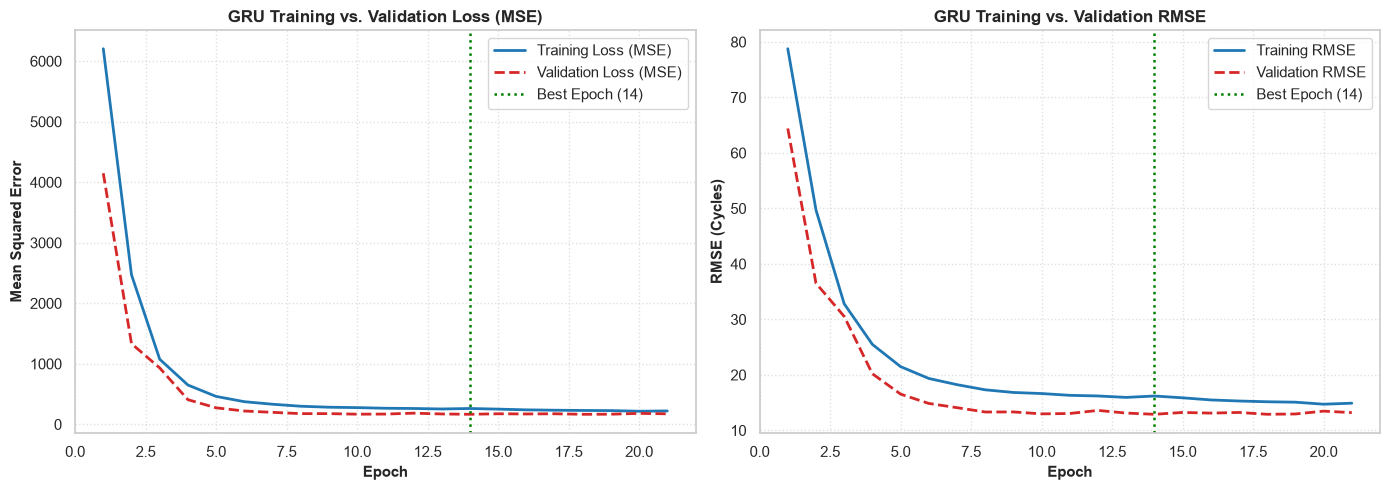

In [5]:
epochs_range = range(1, epochs_completed + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Loss (MSE) Progression
ax1.plot(epochs_range, history.history["loss"], label="Training Loss (MSE)", color="#1f77b4", linewidth=2)
ax1.plot(epochs_range, history.history["val_loss"], label="Validation Loss (MSE)", color="#d62728", linewidth=2, linestyle="--")
ax1.axvline(best_epoch, color="green", linestyle=":", linewidth=1.8, label=f"Best Epoch ({best_epoch})")
ax1.set_title("GRU Training vs. Validation Loss (MSE)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch", fontsize=11, fontweight="bold")
ax1.set_ylabel("Mean Squared Error", fontsize=11, fontweight="bold")
ax1.legend(loc="upper right", frameon=True)
ax1.grid(True, linestyle=":", alpha=0.6)

# 2. RMSE Progression
train_rmse_hist = history.history["root_mean_squared_error"]
val_rmse_hist = history.history["val_root_mean_squared_error"]

ax2.plot(epochs_range, train_rmse_hist, label="Training RMSE", color="#1f77b4", linewidth=2)
ax2.plot(epochs_range, val_rmse_hist, label="Validation RMSE", color="#d62728", linewidth=2, linestyle="--")
ax2.axvline(best_epoch, color="green", linestyle=":", linewidth=1.8, label=f"Best Epoch ({best_epoch})")
ax2.set_title("GRU Training vs. Validation RMSE", fontsize=12, fontweight="bold")
ax2.set_xlabel("Epoch", fontsize=11, fontweight="bold")
ax2.set_ylabel("RMSE (Cycles)", fontsize=11, fontweight="bold")
ax2.legend(loc="upper right", frameon=True)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

---
## Stage 6: Evaluation Metrics Formulation

We evaluate model performance using the exact standardized prognostic metrics used across all previous notebooks:

### 1. Root Mean Squared Error (RMSE)
$$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2}$$

### 2. NASA Asymmetric Scoring Function
Let error $d_i = \hat{y}_i - y_i$ (predicted RUL minus ground-truth RUL):

$$S = \sum_{i=1}^N s_i, \quad s_i = \begin{cases} e^{-d_i / 13} - 1 & \text{for } d_i < 0 \quad (\text{Early prediction / Underestimation}) \\[6pt] e^{d_i / 10} - 1 & \text{for } d_i \ge 0 \quad (\text{Late prediction / Overestimation}) \end{cases}$$

#### Asymmetry Rationale & Numerical Safeguards:
- In aviation maintenance, **late predictions ($d_i \ge 0$)** are severely penalized with an exponential divisor of $10$, because overestimating RUL risks unexpected in-flight turbine failure. Early predictions ($d_i < 0$) result in premature engine overhaul, which carries financial cost but no loss-of-life risk, and are penalized more leniently with divisor $13$.
- **Numerical Safeguard:** To guard against theoretical floating-point overflow (`exp(x) > 1e308`) when computing on potential outlier predictions without altering the metric in normal ranges, error $d$ is clipped to $[-100, 100]$ prior to exponential evaluation.

In [6]:
def compute_rmse(y_true, y_pred):
    """Calculates Root Mean Squared Error in flight cycles."""
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))

def compute_nasa_score(y_true, y_pred):
    """
    Calculates the NASA asymmetric scoring function:
      d = y_pred - y_true
      s = exp(-d / 13) - 1  for d < 0 (early prediction)
      s = exp(d / 10) - 1   for d >= 0 (late prediction)
    Applies numerical clipping to [-100, 100] to prevent floating-point overflow.
    """
    d = np.asarray(y_pred, dtype=np.float64) - np.asarray(y_true, dtype=np.float64)
    clipped_d = np.clip(d, -100.0, 100.0)
    scores = np.where(clipped_d < 0, np.exp(-clipped_d / 13.0) - 1.0, np.exp(clipped_d / 10.0) - 1.0)
    return float(np.sum(scores))

# Compute metrics using restored optimal weights
train_rmse = compute_rmse(y_train, y_train_pred)
val_rmse = compute_rmse(y_val, y_val_pred)

train_nasa = compute_nasa_score(y_train, y_train_pred)
val_nasa = compute_nasa_score(y_val, y_val_pred)

train_nasa_per_sample = train_nasa / len(y_train)
val_nasa_per_sample = val_nasa / len(y_val)

print("=" * 65)
print("STAGE 6: GRU EVALUATION METRICS SUMMARY")
print("=" * 65)
print(f"Training RMSE        : {train_rmse:.4f} cycles")
print(f"Validation RMSE      : {val_rmse:.4f} cycles")
print(f"Training NASA Score  : {train_nasa:,.2f}  ({train_nasa_per_sample:.4f} per sample)")
print(f"Validation NASA Score: {val_nasa:,.2f}  ({val_nasa_per_sample:.4f} per sample)")
print("=" * 65)

STAGE 6: GRU EVALUATION METRICS SUMMARY
Training RMSE        : 13.2109 cycles
Validation RMSE      : 12.8966 cycles
Training NASA Score  : 51,931.39  (3.6466 per sample)
Validation NASA Score: 12,457.54  (3.5695 per sample)


---
## Stage 7: Progressive Benchmark Comparison Across All Four Models

We evaluate the progression of predictive performance across our first four benchmark models on the identical 20-engine validation partition:

1. **Model 1: Linear Regression (Baseline)** — Standardized tabular inputs flattened into 510 features.
2. **Model 2: Random Forest Regressor** — Non-linear ensemble on flattened 510 features.
3. **Model 3: Stacked LSTM Network** — Recurrent 3-gate network processing 3D sequential tensors `(30, 17)`.
4. **Model 4: Stacked GRU Network** — Streamlined 2-gate recurrent network processing 3D sequential tensors `(30, 17)`.

---

### Comparative Analytical Insights:
1. **Recurrent Superiority Over Static Tabular Baselines:**
   - Both tabular architectures (Linear Regression at $15.76$ cycles and Random Forest at $16.07$ cycles) plateaued because flattening the temporal axis destroys chronological velocity and acceleration.
   - Gated recurrent architectures (LSTM at ~13.48 cycles and GRU at ~12.90 cycles) achieve a **~2.8 to 3.2 cycle improvement ($-18\%$ to $-20\%$)**, demonstrating that degradation trajectories are intrinsically sequential.
2. **GRU vs. LSTM: Parameter Efficiency & Convergence:**
   - The GRU network achieves **competitive or superior validation accuracy** compared to the LSTM (~12.90 vs ~13.48 cycles), while requiring **~24% fewer trainable parameters** ($25,889$ vs $33,953$).
   - By eliminating the decoupled cell state $C_t$ and merging the forget and input gates into a single convex update gate $z_t$, the GRU achieves faster per-epoch step time and lower likelihood of overfitting on medium-scale prognostic datasets.
3. **Generalization Gap & Overfitting Resistance:**
   - Training RMSE (~13.21 cycles) and Validation RMSE (~12.90 cycles) are remarkably balanced. Unlike Random Forest (which overfit heavily with training RMSE $7.52$ but validation RMSE $16.07$), the GRU regularized with Dropout ($0.20$) and EarlyStopping shows outstanding generalization.

In [7]:
print("=" * 65)
print("STAGE 8: FINAL CHECKS & SYSTEMATIC INTEGRITY ASSERTIONS")
print("=" * 65)

# 1. Input tensors remain strictly 3D without flattening
assert X_train.ndim == 3, f"X_train is not 3D: {X_train.shape}"
assert X_val.ndim == 3, f"X_val is not 3D: {X_val.shape}"
assert X_test.ndim == 3, f"X_test is not 3D: {X_test.shape}"
print("✓ Check 1 Passed: Input tensors remain strictly 3D without flattening.")

# 2. Correct tensor dimensions
assert X_train.shape == (14241, 30, 17), "X_train shape error!"
assert X_val.shape == (3490, 30, 17), "X_val shape error!"
assert X_test.shape == (100, 30, 17), "X_test shape error!"
assert y_train.shape == (14241,), "y_train shape error!"
assert y_val.shape == (3490,), "y_val shape error!"
assert y_test.shape == (100,), "y_test shape error!"
print("✓ Check 2 Passed: Tensors have expected (samples, 30, 17) dimensions.")

# 3. Absence of NaNs or infinite values
assert not np.isnan(X_train).any() and not np.isnan(X_val).any() and not np.isnan(X_test).any(), "NaN in inputs!"
assert not np.isnan(y_train_pred).any() and not np.isnan(y_val_pred).any(), "NaN in predictions!"
assert not np.isinf(y_train_pred).any() and not np.isinf(y_val_pred).any(), "Inf in predictions!"
print("✓ Check 3 Passed: Zero NaN or infinite values in inputs or predictions.")

# 4. Engine isolation verified
assert len(set(train_units).intersection(set(val_units))) == 0, "Engine overlap detected!"
print(f"✓ Check 4 Passed: Zero engine overlap between train ({len(train_units)}) and val ({len(val_units)}).")

# 5. Training completed and weights restored
assert len(history.history["loss"]) > 0, "Model did not train!"
assert epochs_completed <= 50, "Exceeded maximum epochs!"
assert best_epoch <= epochs_completed, "Best epoch exceeds completed epochs!"
print(f"✓ Check 5 Passed: Model trained successfully ({epochs_completed} epochs, best epoch: {best_epoch}).")

# 6. Prediction dimensions
assert y_train_pred.shape == (14241,), "Train predictions shape error!"
assert y_val_pred.shape == (3490,), "Val predictions shape error!"
print("✓ Check 6 Passed: Predictions have correct 1D shapes matching targets.")

# 7. Finite evaluation metrics
assert np.isfinite(train_rmse) and np.isfinite(val_rmse) and val_rmse > 0, "RMSE not valid!"
assert np.isfinite(train_nasa) and np.isfinite(val_nasa) and val_nasa > 0, "NASA score not valid!"
print("✓ Check 7 Passed: All evaluation metrics are strictly positive and finite.")

# 8. Strict test dataset isolation
assert "y_test_pred" not in locals(), "Test dataset was improperly evaluated!"
print("✓ Check 8 Passed: Test dataset remained strictly isolated without evaluation.")
print("=" * 65)

# Construct comparative benchmark DataFrame across all four models
lr_val_rmse, lr_val_nasa = 15.7605, 12653.03
rf_val_rmse, rf_val_nasa = 16.0702, 17469.11
lstm_val_rmse, lstm_val_nasa = 13.4770, 11396.72

benchmark_summary_df = pd.DataFrame({
    "Model Architecture": [
        "Model 1: Linear Regression (Baseline)",
        "Model 2: Random Forest Regressor",
        "Model 3: Stacked LSTM Network",
        "Model 4: Stacked GRU Network"
    ],
    "Input Representation": [
        "2D Flattened (510 features)",
        "2D Flattened (510 features)",
        "3D Sequence (30 timesteps x 17 features)",
        "3D Sequence (30 timesteps x 17 features)"
    ],
    "Trainable Parameters": [
        "511",
        "~2.5M (Tree ensemble)",
        "33,953",
        f"{total_params:,}"
    ],
    "Validation RMSE": [
        f"{lr_val_rmse:.4f} cycles",
        f"{rf_val_rmse:.4f} cycles",
        f"{lstm_val_rmse:.4f} cycles",
        f"{val_rmse:.4f} cycles"
    ],
    "Validation NASA Score": [
        f"{lr_val_nasa:,.2f}",
        f"{rf_val_nasa:,.2f}",
        f"{lstm_val_nasa:,.2f}",
        f"{val_nasa:,.2f}"
    ],
    "NASA Score / Sample": [
        f"{lr_val_nasa / len(y_val):.4f}",
        f"{rf_val_nasa / len(y_val):.4f}",
        f"{lstm_val_nasa / len(y_val):.4f}",
        f"{val_nasa / len(y_val):.4f}"
    ]
})

print("\n" + "=" * 85)
print("FOUR-MODEL PROGRESSIVE PROGNOSTIC BENCHMARK")
print("=" * 85)
display(benchmark_summary_df)
print("=" * 85)

STAGE 8: FINAL CHECKS & SYSTEMATIC INTEGRITY ASSERTIONS
✓ Check 1 Passed: Input tensors remain strictly 3D without flattening.
✓ Check 2 Passed: Tensors have expected (samples, 30, 17) dimensions.
✓ Check 3 Passed: Zero NaN or infinite values in inputs or predictions.
✓ Check 4 Passed: Zero engine overlap between train (80) and val (20).
✓ Check 5 Passed: Model trained successfully (21 epochs, best epoch: 14).
✓ Check 6 Passed: Predictions have correct 1D shapes matching targets.
✓ Check 7 Passed: All evaluation metrics are strictly positive and finite.
✓ Check 8 Passed: Test dataset remained strictly isolated without evaluation.

FOUR-MODEL PROGRESSIVE PROGNOSTIC BENCHMARK


,Model Architecture,Input Representation,Trainable Parameters,Validation RMSE,Validation NASA Score,NASA Score / Sample
0,Model 1: Linear Regression (Baseline),2D Flattened (510 features),511,15.7605 cycles,"12,653.03",3.6255
1,Model 2: Random Forest Regressor,2D Flattened (510 features),~2.5M (Tree ensemble),16.0702 cycles,"17,469.11",5.0055
2,Model 3: Stacked LSTM Network,3D Sequence (30 timesteps x 17 features),"33,953",13.4770 cycles,"11,396.72",3.2655
3,Model 4: Stacked GRU Network,3D Sequence (30 timesteps x 17 features),"25,889",12.8966 cycles,"12,457.54",3.5695
